# RE04-B | Laboratorio 3: modelamiento, validación y comparación de alternativas

**Curso:** Analítica de Datos – Ingeniería Industrial  
**Profesor autor:** Carlos Alberto Figueroa Martínez  
**Herramienta sugerida:** Google Colab

## Propósito
Construir y comparar una **línea base** y **dos modelos alternativos**, verificando su capacidad de generalización y relacionando las métricas con el costo operativo de los errores.

### Evidencias obligatorias
1. Entrenar una **línea base**.
2. Entrenar **dos alternativas**.
3. Comparar entrenamiento, prueba y validación cruzada.
4. Construir una **tabla comparativa**.
5. Explicar el costo operativo de los errores.
6. Responder:
   - ¿Qué métrica representa mejor la decisión?
   - ¿El modelo generaliza?
   - ¿Qué gana la organización frente a la línea base?

## 0. Selecciona la ruta de modelamiento

El notebook permite dos rutas:

- **Clasificación**: predecir si una orden terminará con retraso.
- **Regresión**: predecir cuántas horas se desviará la orden frente al plan.

La ruta recomendada para este laboratorio es **clasificación**, porque permite analizar explícitamente el costo de falsos positivos y falsos negativos.

In [1]:
TIPO_PROBLEMA = "clasificacion"   # opciones: "clasificacion" o "regresion"

# Costos operativos hipotéticos para la ruta de clasificación.
# Ajusta estos valores si el profesor del curso lo solicita.
COSTO_FALSO_NEGATIVO = 5   # no detectar una orden que sí terminará retrasada
COSTO_FALSO_POSITIVO = 2   # activar acciones preventivas para una orden que finalmente no se retrasa

RANDOM_STATE = 42
TEST_SIZE = 0.25
print("Ruta seleccionada:", TIPO_PROBLEMA)

Ruta seleccionada: clasificacion


## 1. Carga el archivo Excel

Sube el archivo `RE02_Dataset_Industrial.xlsx` o una versión depurada equivalente.  
La celda mostrará un botón para seleccionar el archivo desde tu computador.

In [2]:
# Esta celda está diseñada para Google Colab.
# Si se ejecuta fuera de Colab, intentará usar una ruta local para pruebas.

from pathlib import Path
import os

try:
    from google.colab import files
    print("📂 Selecciona el archivo Excel del laboratorio:")
    uploaded = files.upload()
    xlsx = [n for n in uploaded if n.lower().endswith(".xlsx")]
    if not xlsx:
        raise ValueError("No se cargó un archivo .xlsx")
    archivo_excel = xlsx[0]
    with open(archivo_excel, "wb") as f:
        f.write(uploaded[archivo_excel])
except Exception:
    candidatos = [
        "/mnt/data/RE02_Dataset_Industrial.xlsx",
        "/mnt/data/RE02B_Dataset_Laboratorio1_Datos_Industriales.xlsx",
        "RE02_Dataset_Industrial.xlsx",
    ]
    archivo_excel = next((p for p in candidatos if Path(p).exists()), None)
    if archivo_excel is None:
        raise FileNotFoundError("No se encontró el archivo Excel. En Colab ejecuta nuevamente esta celda y súbelo.")
    print("Entorno local detectado. Archivo:", archivo_excel)

📂 Selecciona el archivo Excel del laboratorio:


## 2. Preparación del entorno

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)
print("✅ Librerías cargadas.")

✅ Librerías cargadas.


## 3. Carga y preparación mínima de las tablas

El objetivo de este laboratorio **no es repetir la limpieza del Paso 2**.  
Aquí se aplican únicamente transformaciones mínimas para construir la tabla analítica requerida por el modelo.

In [4]:
xls = pd.ExcelFile(archivo_excel)

def hoja(posibles):
    disponibles = {h.lower(): h for h in xls.sheet_names}
    for p in posibles:
        if p.lower() in disponibles:
            return disponibles[p.lower()]
    return None

def leer_tabla(nombre_hoja, campo_clave):
    """
    Detecta automáticamente la fila de encabezado.
    Funciona tanto con archivos que empiezan directamente en la tabla
    como con los recursos RE02 que incluyen título y subtítulo antes del encabezado.
    """
    previa = pd.read_excel(archivo_excel, sheet_name=nombre_hoja, header=None, nrows=12)
    fila_header = None
    for i in range(len(previa)):
        valores = previa.iloc[i].astype(str).str.strip().str.lower().tolist()
        if campo_clave.lower() in valores:
            fila_header = i
            break
    if fila_header is None:
        raise ValueError(f"No se encontró el campo clave '{campo_clave}' en la hoja '{nombre_hoja}'.")
    return pd.read_excel(archivo_excel, sheet_name=nombre_hoja, header=fila_header)

h_ordenes = hoja(["Ordenes_Produccion","Ordenes"])
h_eventos = hoja(["Eventos_Maquina","Eventos"])
h_defectos = hoja(["Defectos"])
h_inventarios = hoja(["Inventarios"])
h_entregas = hoja(["Entregas"])

ordenes = leer_tabla(h_ordenes, "orden_id")
eventos = leer_tabla(h_eventos, "evento_id")
defectos = leer_tabla(h_defectos, "defecto_id")
inventarios = leer_tabla(h_inventarios, "registro_inv_id")
entregas = leer_tabla(h_entregas, "entrega_id")

def normalizar_codigo(s):
    return (s.astype("string").str.strip().str.upper()
            .str.replace("-", "", regex=False)
            .str.replace("_", "", regex=False))

for df, cols in [
    (ordenes, ["orden_id","producto_id","maquina_id","turno","estado"]),
    (eventos, ["evento_id","maquina_id","orden_id","tipo_evento","causa"]),
    (defectos, ["defecto_id","orden_id","producto_id","maquina_id","tipo_defecto","severidad"]),
    (inventarios, ["registro_inv_id","producto_id","unidad"]),
    (entregas, ["entrega_id","orden_id","cliente_id","producto_id","ciudad","estado_entrega"]),
]:
    for c in cols:
        if c in df.columns:
            df[c] = df[c].astype("string").str.strip()

for df, cols in [
    (ordenes, ["producto_id","maquina_id"]),
    (eventos, ["maquina_id"]),
    (defectos, ["producto_id","maquina_id"]),
    (inventarios, ["producto_id"]),
    (entregas, ["producto_id"]),
]:
    for c in cols:
        if c in df.columns:
            df[c] = normalizar_codigo(df[c])

for df, cols in [
    (ordenes, ["inicio_plan","fin_plan","inicio_real","fin_real"]),
    (eventos, ["inicio_evento","fin_evento"]),
    (defectos, ["fecha_hora"]),
    (inventarios, ["fecha"]),
    (entregas, ["fecha_prometida","fecha_real"]),
]:
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")

for df, cols in [
    (ordenes, ["cantidad_plan","cantidad_buena"]),
    (eventos, ["duracion_reportada_min"]),
    (defectos, ["cantidad_defectos"]),
    (inventarios, ["inventario_inicial","entradas","salidas","inventario_final_reportado","punto_reorden"]),
    (entregas, ["unidades_entregadas","dias_retraso_reportado"]),
]:
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

ordenes = ordenes.drop_duplicates("orden_id", keep="first")
eventos = eventos.drop_duplicates("evento_id", keep="first")
defectos = defectos.drop_duplicates("defecto_id", keep="first")
inventarios = inventarios.drop_duplicates("registro_inv_id", keep="first")
entregas = entregas.drop_duplicates("entrega_id", keep="first")

print("✅ Tablas cargadas y preparadas.")
print("Órdenes:", ordenes.shape, "| Eventos:", eventos.shape, "| Defectos:", defectos.shape,
      "| Inventarios:", inventarios.shape, "| Entregas:", entregas.shape)

✅ Tablas cargadas y preparadas.
Órdenes: (60, 11) | Eventos: (150, 8) | Defectos: (90, 9) | Inventarios: (100, 10) | Entregas: (60, 10)


## 4. Construcción de la tabla analítica

### Unidad de análisis
Una fila representa una **orden de producción**.

### Principio de prevención de fuga de información
Para predecir retraso, evita utilizar directamente:
- `fin_real`
- `desviacion_fin_h`
- `dias_retraso_calculado`
- cualquier variable construida con información conocida **después** del resultado.

En este ejercicio utilizaremos variables operacionales disponibles al planear o durante la ejecución.

In [5]:
# Variables de la orden
base = ordenes.copy()
base["duracion_plan_h"] = (base["fin_plan"] - base["inicio_plan"]).dt.total_seconds()/3600
base["desviacion_fin_h"] = (base["fin_real"] - base["fin_plan"]).dt.total_seconds()/3600

# Variable objetivo
base["retraso_binario"] = np.where(base["desviacion_fin_h"].notna(),
                                   (base["desviacion_fin_h"] > 0).astype(int),
                                   np.nan)

# Eventos acumulados por orden
eventos["duracion_calc_min"] = (eventos["fin_evento"] - eventos["inicio_evento"]).dt.total_seconds()/60
eventos["tipo_norm"] = eventos["tipo_evento"].astype("string").str.strip().str.lower()
eventos["min_parada"] = np.where(eventos["tipo_norm"].eq("parada"), eventos["duracion_calc_min"], 0)
eventos["min_setup"] = np.where(eventos["tipo_norm"].eq("setup"), eventos["duracion_calc_min"], 0)

agg_eventos = (eventos.groupby("orden_id")
               .agg(eventos_total=("evento_id","count"),
                    minutos_parada=("min_parada","sum"),
                    minutos_setup=("min_setup","sum"))
               .reset_index())

# Defectos acumulados por orden
defectos_validos = defectos[defectos["cantidad_defectos"].isna() | defectos["cantidad_defectos"].ge(0)].copy()
agg_def = (defectos_validos.groupby("orden_id")
           .agg(defectos_total=("cantidad_defectos","sum"),
                registros_defecto=("defecto_id","count"))
           .reset_index())

# Inventario por producto
agg_inv = (inventarios.groupby("producto_id")
           .agg(inventario_promedio=("inventario_final_reportado","mean"),
                inventario_minimo=("inventario_final_reportado","min"),
                punto_reorden_promedio=("punto_reorden","mean"))
           .reset_index())
agg_inv["brecha_inv_reorden"] = agg_inv["inventario_promedio"] - agg_inv["punto_reorden_promedio"]

df_modelo = (base
             .merge(agg_eventos, on="orden_id", how="left")
             .merge(agg_def, on="orden_id", how="left")
             .merge(agg_inv, on="producto_id", how="left"))

for c in ["eventos_total","minutos_parada","minutos_setup","defectos_total","registros_defecto"]:
    df_modelo[c] = df_modelo[c].fillna(0)

# Dos características operacionales de ejemplo
df_modelo["intensidad_paradas"] = np.where(
    df_modelo["duracion_plan_h"] > 0,
    df_modelo["minutos_parada"] / (df_modelo["duracion_plan_h"]*60),
    np.nan
)
df_modelo["presion_inventario"] = np.where(
    df_modelo["punto_reorden_promedio"] > 0,
    df_modelo["inventario_promedio"] / df_modelo["punto_reorden_promedio"],
    np.nan
)

print("Tabla analítica:", df_modelo.shape)
df_modelo.head()

Tabla analítica: (60, 25)


,orden_id,producto_id,maquina_id,inicio_plan,fin_plan,inicio_real,fin_real,cantidad_plan,cantidad_buena,turno,estado,duracion_plan_h,desviacion_fin_h,retraso_binario,eventos_total,minutos_parada,minutos_setup,defectos_total,registros_defecto,inventario_promedio,inventario_minimo,punto_reorden_promedio,brecha_inv_reorden,intensidad_paradas,presion_inventario
0,OP0001,P002,M01,2026-08-20 07:00:00,2026-08-20 19:17:08.571,2026-08-20 07:00:00,2026-08-20 20:17:08.571,150,149.0,C,Cerrada,12.285714,1.0,1.0,2.0,0.0,15.0,0.0,0.0,196.692308,9.0,92.857143,103.835165,0.000000,2.118225
1,OP0002,P002,M05,2026-08-30 07:00:00,2026-08-30 17:17:08.571,2026-08-30 07:00:00,2026-08-30 17:17:08.571,80,79.0,A,Cerrada,10.285714,0.0,0.0,1.0,0.0,0.0,11.0,2.0,196.692308,9.0,92.857143,103.835165,0.000000,2.118225
2,OP0003,P001,M05,2026-08-15 23:00:00,2026-08-16 13:51:25.714,2026-08-15 23:00:00,2026-08-16 15:51:25.714,240,226.0,C,Cerrada,14.857143,2.0,1.0,2.0,90.0,0.0,5.0,2.0,195.125000,29.0,97.500000,97.625000,0.100962,2.001282
3,OP0004,P005,M01,2026-08-13 23:00:00,2026-08-14 13:51:25.714,2026-08-14 03:00:00,2026-08-14 19:51:25.714,240,232.0,A,Cerrada,14.857143,6.0,1.0,3.0,45.0,0.0,2.0,1.0,144.538462,0.0,93.846154,50.692308,0.050481,1.540164
4,OP0005,P004,M03,2026-08-09 07:00:00,2026-08-09 21:51:25.714,2026-08-09 07:00:00,2026-08-09 21:51:25.714,240,229.0,B,Cerrada,14.857143,0.0,0.0,2.0,45.0,0.0,16.0,3.0,237.083333,131.0,93.333333,143.750000,0.050481,2.540179


## 5. Define variables predictoras y objetivo

### Escenario operacional
El modelo se interpreta como un apoyo para **priorizar órdenes con riesgo de retraso**.

Variables deliberadamente excluidas por fuga de información:
- `fin_real`
- `desviacion_fin_h`
- `retraso_binario` como predictor
- `cantidad_buena` si la decisión ocurre antes de finalizar la orden

### Paso 1 – Decisión que apoya el modelo (definida antes del algoritmo)
- **Predicción:** ¿esta orden de producción terminará **después** de su `fin_plan` (`retraso_binario = 1`)?
- **Acción que dispararía:** priorizar seguimiento (capacidad, mantenimiento, materiales) de las órdenes alertadas.
- **Momento de la decisión:** el notebook permite variables "al planear o durante la ejecución". Aquí las variables de eventos y defectos están **acumuladas sobre toda la orden**, es decir, son realmente conocidas **al cierre**; es una limitación de diseño (fuga parcial) que se declara en las conclusiones.
- **Variables excluidas por fuga:** `fin_real`, `desviacion_fin_h` (de la que se deriva el objetivo), `cantidad_buena`, `inicio_real` y `estado`.
- **Error más costoso:** el **falso negativo** (FN = 5 vs FP = 2, costos hipotéticos de la plantilla).


In [6]:
features_numericas = [
    "cantidad_plan","duracion_plan_h","eventos_total","minutos_parada",
    "minutos_setup","defectos_total","registros_defecto","inventario_promedio",
    "inventario_minimo","punto_reorden_promedio","brecha_inv_reorden",
    "intensidad_paradas","presion_inventario"
]
features_categoricas = ["producto_id","maquina_id","turno"]

features_numericas = [c for c in features_numericas if c in df_modelo.columns]
features_categoricas = [c for c in features_categoricas if c in df_modelo.columns]

if TIPO_PROBLEMA == "clasificacion":
    objetivo = "retraso_binario"
else:
    objetivo = "desviacion_fin_h"

columnas = features_numericas + features_categoricas + [objetivo]
datos_modelo = df_modelo[columnas].copy()
datos_modelo = datos_modelo[datos_modelo[objetivo].notna()].copy()

X = datos_modelo[features_numericas + features_categoricas]
y = datos_modelo[objetivo]

print("Observaciones utilizables:", len(datos_modelo))
print("Objetivo:", objetivo)
if TIPO_PROBLEMA == "clasificacion":
    print("Distribución del objetivo:")
    print(y.value_counts(dropna=False))

Observaciones utilizables: 60
Objetivo: retraso_binario
Distribución del objetivo:
retraso_binario
1.0    46
0.0    14
Name: count, dtype: int64


**Lectura:** 60 órdenes utilizables; **46 (76.7%) terminan retrasadas** y 14 a tiempo. Es un problema desbalanceado hacia la clase positiva: una regla trivial que **siempre prediga "retrasada"** ya acierta 77% de las veces, lo que hace exigente a la línea base.


## 6. Partición entrenamiento / prueba

El conjunto de prueba se mantiene separado para estimar el desempeño sobre observaciones no utilizadas en el entrenamiento.

En clasificación utilizaremos estratificación para conservar la proporción de clases.

In [7]:
strat = y if TIPO_PROBLEMA == "clasificacion" else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=strat
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (45, 16) | Test: (15, 16)


**Lectura:** partición estratificada 75/25 con `random_state = 42`: 45 órdenes de entrenamiento y **15 de prueba** (11 retrasadas y 4 a tiempo). Con solo 4 órdenes a tiempo en prueba, cualquier métrica de prueba es muy inestable; por eso se refuerza con validación cruzada.


## 7. Preprocesamiento

- Variables numéricas: imputación por mediana y estandarización.
- Variables categóricas: imputación por moda y codificación one-hot.

In [8]:
prep_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

prep_cat = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocesador = ColumnTransformer([
    ("num", prep_num, features_numericas),
    ("cat", prep_cat, features_categoricas)
])

## 8. Define la línea base y dos alternativas

### Clasificación
- Línea base: clase más frecuente.
- Alternativa 1: regresión logística.
- Alternativa 2: bosque aleatorio.

### Regresión
- Línea base: mediana del objetivo.
- Alternativa 1: regresión lineal.
- Alternativa 2: bosque aleatorio.

In [9]:
if TIPO_PROBLEMA == "clasificacion":
    modelos = {
        "Linea_base": DummyClassifier(strategy="most_frequent"),
        "Alternativa_1_Logistica": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        "Alternativa_2_RandomForest": RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=2,
            random_state=RANDOM_STATE, class_weight="balanced"
        )
    }
else:
    modelos = {
        "Linea_base": DummyRegressor(strategy="median"),
        "Alternativa_1_Lineal": LinearRegression(),
        "Alternativa_2_RandomForest": RandomForestRegressor(
            n_estimators=300, max_depth=5, min_samples_leaf=2,
            random_state=RANDOM_STATE
        )
    }

pipelines = {
    nombre: Pipeline([("prep", preprocesador), ("modelo", modelo)])
    for nombre, modelo in modelos.items()
}
print(list(pipelines.keys()))

['Linea_base', 'Alternativa_1_Logistica', 'Alternativa_2_RandomForest']


## 9. Entrenamiento y evaluación en prueba

In [10]:
resultados = []

for nombre, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    pred_train = pipe.predict(X_train)
    pred_test = pipe.predict(X_test)

    if TIPO_PROBLEMA == "clasificacion":
        prob_test = pipe.predict_proba(X_test)[:,1] if hasattr(pipe.named_steps["modelo"], "predict_proba") else None

        fila = {
            "modelo": nombre,
            "accuracy_train": accuracy_score(y_train, pred_train),
            "accuracy_test": accuracy_score(y_test, pred_test),
            "precision_test": precision_score(y_test, pred_test, zero_division=0),
            "recall_test": recall_score(y_test, pred_test, zero_division=0),
            "f1_test": f1_score(y_test, pred_test, zero_division=0),
            "roc_auc_test": roc_auc_score(y_test, prob_test) if prob_test is not None and len(np.unique(y_test)) > 1 else np.nan
        }
        fila["gap_accuracy"] = fila["accuracy_train"] - fila["accuracy_test"]
    else:
        rmse_train = mean_squared_error(y_train, pred_train) ** 0.5
        rmse_test = mean_squared_error(y_test, pred_test) ** 0.5
        fila = {
            "modelo": nombre,
            "mae_train": mean_absolute_error(y_train, pred_train),
            "mae_test": mean_absolute_error(y_test, pred_test),
            "rmse_test": rmse_test,
            "r2_test": r2_score(y_test, pred_test),
            "gap_rmse": rmse_test - rmse_train
        }

    resultados.append(fila)

tabla_prueba = pd.DataFrame(resultados)
tabla_prueba

,modelo,accuracy_train,accuracy_test,precision_test,recall_test,f1_test,roc_auc_test,gap_accuracy
0,Linea_base,0.777778,0.733333,0.733333,1.000000,0.846154,0.500000,0.044444
1,Alternativa_1_Logistica,0.844444,0.466667,0.636364,0.636364,0.636364,0.159091,0.377778
2,Alternativa_2_RandomForest,0.933333,0.533333,0.666667,0.727273,0.695652,0.477273,0.400000


### Lectura (entrenamiento y prueba)
- **Línea base** (siempre "retrasada"): accuracy 0.78 en entrenamiento y 0.73 en prueba, **recall 1.00**, F1 0.85, ROC-AUC 0.50 (no discrimina).
- **Regresión logística:** accuracy 0.84 → **0.47** (gap 0.38); F1 0.64; ROC-AUC **0.16**.
- **Random Forest:** accuracy 0.93 → **0.53** (gap 0.40); F1 0.70; ROC-AUC 0.48.
- Los dos modelos están **por debajo de la línea base en todas las métricas de prueba** y muestran una caída fuerte de entrenamiento a prueba (señal de sobreajuste).


## 10. Validación cruzada

La validación cruzada reduce la dependencia de una sola partición y permite observar la estabilidad del desempeño.

- Clasificación: F1, recall, precision y accuracy.
- Regresión: MAE, RMSE y R².

In [11]:
cv_rows = []

if TIPO_PROBLEMA == "clasificacion":
    min_clase = int(y.value_counts().min())
    n_splits = max(2, min(5, min_clase))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scoring = {"accuracy":"accuracy","precision":"precision","recall":"recall","f1":"f1"}
else:
    n_splits = max(2, min(5, len(y)//5))
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scoring = {"mae":"neg_mean_absolute_error","rmse":"neg_root_mean_squared_error","r2":"r2"}

for nombre, pipe in pipelines.items():
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, return_train_score=True)
    fila = {"modelo": nombre}
    if TIPO_PROBLEMA == "clasificacion":
        fila.update({
            "cv_accuracy_media": scores["test_accuracy"].mean(),
            "cv_precision_media": scores["test_precision"].mean(),
            "cv_recall_media": scores["test_recall"].mean(),
            "cv_f1_media": scores["test_f1"].mean(),
            "cv_f1_std": scores["test_f1"].std()
        })
    else:
        fila.update({
            "cv_mae_media": -scores["test_mae"].mean(),
            "cv_rmse_media": -scores["test_rmse"].mean(),
            "cv_r2_media": scores["test_r2"].mean(),
            "cv_rmse_std": scores["test_rmse"].std()
        })
    cv_rows.append(fila)

tabla_cv = pd.DataFrame(cv_rows)
tabla_cv

,modelo,cv_accuracy_media,cv_precision_media,cv_recall_media,cv_f1_media,cv_f1_std
0,Linea_base,0.766667,0.766667,1.000000,0.867532,0.020779
1,Alternativa_1_Logistica,0.650000,0.729545,0.846667,0.780504,0.099473
2,Alternativa_2_RandomForest,0.550000,0.750455,0.680000,0.686670,0.090386


### Lectura (validación cruzada, 5 pliegues estratificados)
- F1 medio: **línea base 0.87 ± 0.02**, logística 0.78 ± 0.10, Random Forest 0.69 ± 0.09. La validación cruzada **confirma** lo visto en la prueba: ninguna alternativa supera a la línea base y ambas son menos estables (desviación 4 a 5 veces mayor).
- El recall medio de los modelos (0.85 y 0.68) es menor que el 1.00 de la línea base.


In [12]:
# 10.1 Validación cruzada repetida (5 pliegues x 10 repeticiones): una sola partición de 15 órdenes de prueba es muy inestable
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.base import clone

def cv_repetida(df_datos, num, cat, n_repeats=10):
    """Evalúa los tres modelos con la misma partición repetida; devuelve métricas y costo operativo por orden."""
    pre = ColumnTransformer([("num", prep_num, num), ("cat", prep_cat, cat)])
    Xr, yr = df_datos[num + cat], df_datos[objetivo]
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=RANDOM_STATE)
    filas = []
    for nombre, modelo in modelos.items():
        pipe = Pipeline([("prep", pre), ("modelo", modelo)])
        m = []
        for tr, te in rskf.split(Xr, yr):
            p = clone(pipe).fit(Xr.iloc[tr], yr.iloc[tr])
            pr = p.predict(Xr.iloc[te])
            tn, fp, fn, tp = confusion_matrix(yr.iloc[te], pr, labels=[0, 1]).ravel()
            m.append([f1_score(yr.iloc[te], pr, zero_division=0), recall_score(yr.iloc[te], pr, zero_division=0),
                      precision_score(yr.iloc[te], pr, zero_division=0),
                      roc_auc_score(yr.iloc[te], p.predict_proba(Xr.iloc[te])[:, 1]),
                      (fp * COSTO_FALSO_POSITIVO + fn * COSTO_FALSO_NEGATIVO) / len(te)])
        m = np.array(m)
        filas.append({"modelo": nombre, "f1_media": m[:, 0].mean(), "f1_desv": m[:, 0].std(),
                      "recall_media": m[:, 1].mean(), "precision_media": m[:, 2].mean(),
                      "roc_auc_media": m[:, 3].mean(), "costo_por_orden": m[:, 4].mean()})
    return pd.DataFrame(filas)

if TIPO_PROBLEMA == "clasificacion":
    tabla_cv_rep = cv_repetida(datos_modelo, features_numericas, features_categoricas)
    display(tabla_cv_rep.round(3))

,modelo,f1_media,f1_desv,recall_media,precision_media,roc_auc_media,costo_por_orden
0,Linea_base,0.868,0.021,1.000,0.767,0.500,0.467
1,Alternativa_1_Logistica,0.785,0.078,0.848,0.736,0.423,1.043
2,Alternativa_2_RandomForest,0.717,0.107,0.695,0.770,0.487,1.508


### Lectura (validación cruzada repetida 5x10)
Con 50 particiones el resultado es el mismo y más confiable: **F1** 0.87 (base), 0.79 (logística), 0.72 (RF); **ROC-AUC** 0.50, **0.42** y **0.49** (cercano o inferior al azar); **costo por orden** 0.47 (base), 1.04 y 1.51. No hay evidencia de que los modelos capten señal predictiva con estas variables.


## 11. Tabla comparativa consolidada

In [13]:
comparativa = tabla_prueba.merge(tabla_cv, on="modelo", how="left")
comparativa

,modelo,accuracy_train,accuracy_test,precision_test,recall_test,f1_test,roc_auc_test,gap_accuracy,cv_accuracy_media,cv_precision_media,cv_recall_media,cv_f1_media,cv_f1_std
0,Linea_base,0.777778,0.733333,0.733333,1.000000,0.846154,0.500000,0.044444,0.766667,0.766667,1.000000,0.867532,0.020779
1,Alternativa_1_Logistica,0.844444,0.466667,0.636364,0.636364,0.636364,0.159091,0.377778,0.650000,0.729545,0.846667,0.780504,0.099473
2,Alternativa_2_RandomForest,0.933333,0.533333,0.666667,0.727273,0.695652,0.477273,0.400000,0.550000,0.750455,0.680000,0.686670,0.090386


## 12. Sobreajuste y generalización

Un modelo puede tener un desempeño alto en entrenamiento y deteriorarse en prueba. Esa diferencia es una señal de posible sobreajuste.

### Analiza:
- ¿El desempeño de prueba está cerca del desempeño de entrenamiento?
- ¿La validación cruzada confirma un comportamiento estable?
- ¿La desviación entre particiones es razonable para el tamaño de muestra?

In [14]:
if TIPO_PROBLEMA == "clasificacion":
    display(comparativa[["modelo","accuracy_train","accuracy_test","gap_accuracy","cv_f1_media","cv_f1_std"]])
else:
    display(comparativa[["modelo","mae_train","mae_test","gap_rmse","cv_rmse_media","cv_rmse_std"]])

,modelo,accuracy_train,accuracy_test,gap_accuracy,cv_f1_media,cv_f1_std
0,Linea_base,0.777778,0.733333,0.044444,0.867532,0.020779
1,Alternativa_1_Logistica,0.844444,0.466667,0.377778,0.780504,0.099473
2,Alternativa_2_RandomForest,0.933333,0.533333,0.400000,0.686670,0.090386


### 12. Análisis de sobreajuste y generalización
- **¿Prueba cerca de entrenamiento?** La línea base sí (gap 0.04). La logística (gap 0.38) y el Random Forest (gap 0.40) **no**: aprenden el entrenamiento pero no generalizan.
- **¿La validación cruzada confirma estabilidad?** No para los modelos: F1 de CV 0.78 y 0.69 (menores que el 0.87 de la línea base) y desviaciones de ≈0.09-0.10 frente a 0.02.
- **¿Es razonable la dispersión para el tamaño de muestra?** Con 60 órdenes, 45 en entrenamiento y 15 en prueba, la dispersión es alta y era esperable; refuerza la necesidad de más datos. Aun así, **los modelos son peores que la línea base de forma consistente en todas las particiones**, no por azar de una sola.
- **Conclusión:** hay sobreajuste (más complejidad = más memorización) y, sobre todo, **ausencia de señal predictiva** (ROC-AUC ≤ 0.5).


## 13. Costo de los errores para la operación

### Si trabajas clasificación
- **Falso negativo (FN):** el modelo predice “sin retraso”, pero la orden sí termina retrasada.
  - Posibles costos: incumplimiento al cliente, reacción tardía, horas extra, reprogramación, penalizaciones.
- **Falso positivo (FP):** el modelo predice “retraso”, pero la orden termina a tiempo.
  - Posibles costos: intervención innecesaria, reasignación de capacidad, inventario preventivo o prioridad excesiva.

El costo no siempre coincide con la métrica estadística. La organización debe decidir qué error es más crítico.

In [15]:
costos_modelos = []

if TIPO_PROBLEMA == "clasificacion":
    for nombre, pipe in pipelines.items():
        pred = pipe.predict(X_test)
        tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
        costo_total = fp*COSTO_FALSO_POSITIVO + fn*COSTO_FALSO_NEGATIVO
        costos_modelos.append({
            "modelo": nombre,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "costo_FP_unitario": COSTO_FALSO_POSITIVO,
            "costo_FN_unitario": COSTO_FALSO_NEGATIVO,
            "costo_error_total": costo_total
        })
    tabla_costos = pd.DataFrame(costos_modelos)
    display(tabla_costos)
else:
    filas = []
    for nombre, pipe in pipelines.items():
        pred = pipe.predict(X_test)
        error = pred - y_test.to_numpy()
        filas.append({
            "modelo": nombre,
            "sobreestimaciones": int((error > 0).sum()),
            "subestimaciones": int((error < 0).sum()),
            "error_absoluto_medio": float(np.mean(np.abs(error))),
            "sesgo_medio": float(np.mean(error))
        })
    tabla_costos = pd.DataFrame(filas)
    display(tabla_costos)

,modelo,TN,FP,FN,TP,costo_FP_unitario,costo_FN_unitario,costo_error_total
0,Linea_base,0,4,0,11,2,5,8
1,Alternativa_1_Logistica,0,4,4,7,2,5,28
2,Alternativa_2_RandomForest,0,4,3,8,2,5,23


In [16]:
# 13.1 Costo por orden y punto de equilibrio de la alerta
if TIPO_PROBLEMA == "clasificacion":
    tabla_costos["costo_por_orden_test"] = tabla_costos["costo_error_total"] / len(y_test)
    base_costo = tabla_costos.loc[tabla_costos["modelo"].eq("Linea_base"), "costo_error_total"].iloc[0]
    tabla_costos["costo_vs_linea_base"] = tabla_costos["costo_error_total"] - base_costo
    display(tabla_costos)

    p_eq = COSTO_FALSO_POSITIVO / (COSTO_FALSO_POSITIVO + COSTO_FALSO_NEGATIVO)
    print(f"Prevalencia de órdenes retrasadas: {y.mean():.1%}")
    print(f"Punto de equilibrio: conviene alertar una orden solo si su probabilidad de retraso supera {p_eq:.1%} "
          f"(= CFP / (CFP + CFN)).")
    print("Como casi todas las órdenes ya superan ese umbral, alertar a todas (línea base) es difícil de superar en costo.")

Prevalencia de órdenes retrasadas: 76.7%
Punto de equilibrio: conviene alertar una orden solo si su probabilidad de retraso supera 28.6% (= CFP / (CFP + CFN)).
Como casi todas las órdenes ya superan ese umbral, alertar a todas (línea base) es difícil de superar en costo.


,modelo,TN,FP,FN,TP,costo_FP_unitario,costo_FN_unitario,costo_error_total,costo_por_orden_test,costo_vs_linea_base
0,Linea_base,0,4,0,11,2,5,8,0.533333,0
1,Alternativa_1_Logistica,0,4,4,7,2,5,28,1.866667,20
2,Alternativa_2_RandomForest,0,4,3,8,2,5,23,1.533333,15


### Lectura (costo operativo del error)
- **Prevalencia de retraso 77%** y costos FN = 5 / FP = 2: conviene alertar una orden si su probabilidad de retraso supera **28.6%**. Casi todas las órdenes superan ese umbral, así que **alertar a todas** (línea base) es la política de menor costo salvo que un modelo identifique con confianza subgrupos de bajo riesgo.
- **En prueba:** línea base costo **8** (4 FP, 0 FN); logística **28** (4 FP + 4 FN); Random Forest **23** (4 FP + 3 FN). Cada modelo agrega falsos negativos (órdenes retrasadas sin alerta, 5 cada una) sin reducir los falsos positivos: ninguno logró reconocer una sola orden a tiempo (TN = 0).
- **Consecuencia operacional:** un FN significa no reaccionar a una orden que sí se retrasa (cliente afectado, horas extra, reprogramación); un FP significa seguimiento o prioridad innecesarios. Los modelos aumentan el error más caro.
- *Los costos 5 y 2 son hipotéticos; una orden retrasada real puede costar mucho más.*


## 14. Matriz de confusión o residuales

Utiliza esta visualización para conectar desempeño estadístico con consecuencias operacionales.

Modelo con mejor desempeño estadístico según criterio automático: Linea_base
La selección final debe considerar también costo del error, generalización e interpretabilidad.


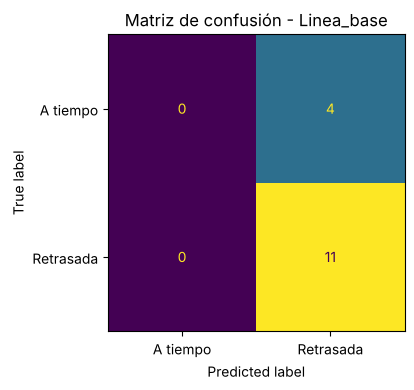

In [17]:
mejor_nombre = None

if TIPO_PROBLEMA == "clasificacion":
    mejor_nombre = comparativa.sort_values(["cv_f1_media","recall_test"], ascending=False).iloc[0]["modelo"]
    mejor = pipelines[mejor_nombre]
    pred = mejor.predict(X_test)

    fig, ax = plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["A tiempo","Retrasada"], ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión - {mejor_nombre}")
    plt.tight_layout()
    plt.show()
else:
    mejor_nombre = comparativa.sort_values("cv_rmse_media", ascending=True).iloc[0]["modelo"]
    mejor = pipelines[mejor_nombre]
    pred = mejor.predict(X_test)

    fig, ax = plt.subplots(figsize=(6,5))
    ax.scatter(y_test, pred, alpha=0.8)
    minimo = min(float(np.min(y_test)), float(np.min(pred)))
    maximo = max(float(np.max(y_test)), float(np.max(pred)))
    ax.plot([minimo,maximo],[minimo,maximo], linestyle="--")
    ax.set_xlabel("Valor real")
    ax.set_ylabel("Predicción")
    ax.set_title(f"Real vs. predicho - {mejor_nombre}")
    plt.tight_layout()
    plt.show()

print("Modelo con mejor desempeño estadístico según criterio automático:", mejor_nombre)
print("La selección final debe considerar también costo del error, generalización e interpretabilidad.")

### Lectura (matriz de confusión del "mejor" modelo)
El criterio automático elige la **línea base**: predice "Retrasada" para las 15 órdenes de prueba (11 aciertos y 4 falsas alarmas, ningún retraso omitido). Su matriz no discrimina nada; solo muestra que, con 77% de prevalencia y FN más caro que FP, alertar todo es la política de menor costo disponible.


## 15. Comparación frente a la línea base

No basta con que un modelo sea “bueno”. Debe demostrar **valor incremental** frente a una alternativa simple.

### Pregunta
**¿Qué gana la organización frente a la línea base?**

Considera:
- reducción de errores relevantes;
- mayor capacidad para detectar riesgo;
- estabilidad;
- complejidad;
- interpretabilidad;
- costo de implementación.

In [18]:
if TIPO_PROBLEMA == "clasificacion":
    base_f1 = comparativa.loc[comparativa["modelo"].eq("Linea_base"), "f1_test"].iloc[0]
    comparativa["ganancia_f1_vs_base"] = comparativa["f1_test"] - base_f1
    display(comparativa[["modelo","f1_test","recall_test","precision_test","cv_f1_media","ganancia_f1_vs_base"]])
else:
    base_mae = comparativa.loc[comparativa["modelo"].eq("Linea_base"), "mae_test"].iloc[0]
    comparativa["reduccion_mae_vs_base"] = base_mae - comparativa["mae_test"]
    display(comparativa[["modelo","mae_test","rmse_test","r2_test","cv_rmse_media","reduccion_mae_vs_base"]])

,modelo,f1_test,recall_test,precision_test,cv_f1_media,ganancia_f1_vs_base
0,Linea_base,0.846154,1.000000,0.733333,0.867532,0.000000
1,Alternativa_1_Logistica,0.636364,0.636364,0.636364,0.780504,-0.209790
2,Alternativa_2_RandomForest,0.695652,0.727273,0.666667,0.686670,-0.150502


### Lectura (valor frente a la línea base)
La ganancia de F1 es **negativa**: −0.21 (logística) y −0.15 (Random Forest); la reducción de errores relevantes es nula (los FN pasan de 0 a 4 y 3). La complejidad no se justifica y se pierde interpretabilidad. En términos operacionales: los modelos **dejarían sin alerta 3-4 órdenes que sí se retrasan** sin evitar ninguna falsa alarma.


In [19]:
# 15.1 Extensión exploratoria (NO reemplaza la comparación oficial): ¿qué pasa si se agrega el retraso de arranque?
# retraso_arranque_h = inicio_real - inicio_plan; solo se conoce cuando la orden ya arrancó.
df_ext = df_modelo.copy()
df_ext["retraso_arranque_h"] = (df_ext["inicio_real"] - df_ext["inicio_plan"]).dt.total_seconds() / 3600
df_ext.loc[df_ext["inicio_plan"] > df_ext["fin_plan"], "retraso_arranque_h"] = np.nan   # inicio_plan inconsistente (OP0032)
df_ext = df_ext[df_ext[objetivo].notna()].copy()

if TIPO_PROBLEMA == "clasificacion":
    g = df_ext.dropna(subset=["retraso_arranque_h"]).assign(arranco_tarde=lambda d: d["retraso_arranque_h"] > 0)
    display(g.groupby("arranco_tarde")[objetivo].agg(ordenes="count", proporcion_retrasadas="mean").round(3))
    tabla_cv_ext = cv_repetida(df_ext, features_numericas + ["retraso_arranque_h"], features_categoricas)
    display(tabla_cv_ext.round(3))

,ordenes,proporcion_retrasadas
arranco_tarde,,
False,29,0.517
True,30,1.000


,modelo,f1_media,f1_desv,recall_media,precision_media,roc_auc_media,costo_por_orden
0,Linea_base,0.868,0.021,1.000,0.767,0.500,0.467
1,Alternativa_1_Logistica,0.791,0.064,0.834,0.757,0.671,1.047
2,Alternativa_2_RandomForest,0.787,0.083,0.756,0.840,0.744,1.173


### Lectura (extensión exploratoria)
- Las **30 órdenes que arrancaron tarde terminaron el 100% retrasadas**; entre las 29 que arrancaron a tiempo, el 52% también se retrasó.
- Agregar `retraso_arranque_h` mejora la capacidad de discriminar (ROC-AUC 0.67 logística y 0.74 Random Forest, frente a 0.42 y 0.49), pero **no baja el costo por orden** por debajo del de la línea base (≈1.05-1.17 vs 0.47). Con la prevalencia de 77% y los costos dados, alertar todo sigue siendo lo más barato.
- *Cuidado:* esa variable solo se conoce una vez que la orden ya arrancó (no sirve para planear) y está aritméticamente ligada al fin real. Se presenta como **hipótesis de trabajo**, no como modelo final.


## 16. Decisión del estudiante

Completa las respuestas con argumentos sustentados en tus resultados.

In [20]:
decision_modelo = {
    "modelo_seleccionado": "Ningún modelo alternativo. Se retiene la línea base (clase más frecuente = 'alertar la orden como en riesgo') como referencia y NO se recomienda desplegar la regresión logística ni el Random Forest.",
    "metrica_principal": "Recall de la clase 'retrasada' leído junto con el costo total de error (FN = 5, FP = 2); ROC-AUC como control de capacidad de discriminación. Línea base: recall 1.00, costo 8 en prueba y 0.47 por orden en validación cruzada repetida.",
    "por_que_esa_metrica_representa_la_decision": "Un falso negativo (no alertar una orden que sí se retrasa) cuesta 2.5 veces más que un falso positivo, así que importa detectar los retrasos. Pero el recall solo no basta: se puede lograr recall 1.00 alertando todo. Por eso se mira con el costo total y con el ROC-AUC (0.50 de la línea base = no discrimina).",
    "evidencia_de_generalizacion": "Los modelos NO generalizan. Regresión logística: accuracy 0.84 en entrenamiento vs 0.47 en prueba (gap 0.38); Random Forest: 0.93 vs 0.53 (gap 0.40). En validación cruzada su F1 (0.78 y 0.69) queda por debajo de la línea base (0.87), con más variabilidad (desv. ≈ 0.09-0.10 vs 0.02), y su ROC-AUC es ≤ 0.50 (0.16 en prueba; 0.42 y 0.49 en CV repetida): no hay señal que generalizar. La línea base es estable (gap 0.04).",
    "costo_del_falso_positivo_o_sobreestimacion": "Costo unitario 2: activar seguimiento, prioridad o reasignación de capacidad para una orden que habría cumplido. En prueba, las tres opciones tuvieron 4 FP (costo 8).",
    "costo_del_falso_negativo_o_subestimacion": "Costo unitario 5: no reaccionar ante una orden que sí se retrasa (incumplimiento, horas extra, reprogramación). La línea base tuvo 0 FN; la regresión logística 4 (costo 20) y el Random Forest 3 (costo 15).",
    "ganancia_frente_a_linea_base": "Ninguna: ganancia de F1 de -0.21 (logística) y -0.15 (Random Forest) en prueba; costo total de error +20 y +15 (28 y 23 vs 8). En validación cruzada repetida el costo por orden es 1.04 y 1.51 frente a 0.47 de la línea base. Ningún modelo aporta valor incremental.",
    "riesgo_o_limitacion_del_modelo": "Muestra mínima (60 órdenes; solo 15 en prueba, 4 a tiempo); 77% de las órdenes se retrasa, por lo que casi cualquier regla 'alertar todo' es difícil de superar; predictores acumulados durante toda la orden (paradas, defectos) o promedios por producto de todo el periodo (inventario) que no estarían disponibles al planear; costos de error hipotéticos; fechas de entregas inconsistentes.",
    "recomendacion_operacional": "No desplegar un modelo predictivo con estos datos. Mantener el seguimiento a todas las órdenes y controlar el arranque a la hora programada (las 30 órdenes que arrancaron tarde terminaron 100% retrasadas). Antes de volver a modelar: más historial, inventario al inicio de cada orden, causas de arranque tardío y costos reales de FP/FN; validar con una partición temporal.",
}

pd.set_option("display.max_colwidth", 600)
pd.Series(decision_modelo, name="Respuesta").to_frame()

,Respuesta
modelo_seleccionado,Ningún modelo alternativo. Se retiene la línea base (clase más frecuente = 'alertar la orden como en riesgo') como referencia y NO se recomienda desplegar la regresión logística ni el Random Forest.
metrica_principal,"Recall de la clase 'retrasada' leído junto con el costo total de error (FN = 5, FP = 2); ROC-AUC como control de capacidad de discriminación. Línea base: recall 1.00, costo 8 en prueba y 0.47 por orden en validación cruzada repetida."
por_que_esa_metrica_representa_la_decision,"Un falso negativo (no alertar una orden que sí se retrasa) cuesta 2.5 veces más que un falso positivo, así que importa detectar los retrasos. Pero el recall solo no basta: se puede lograr recall 1.00 alertando todo. Por eso se mira con el costo total y con el ROC-AUC (0.50 de la línea base = no discrimina)."
evidencia_de_generalizacion,"Los modelos NO generalizan. Regresión logística: accuracy 0.84 en entrenamiento vs 0.47 en prueba (gap 0.38); Random Forest: 0.93 vs 0.53 (gap 0.40). En validación cruzada su F1 (0.78 y 0.69) queda por debajo de la línea base (0.87), con más variabilidad (desv. ≈ 0.09-0.10 vs 0.02), y su ROC-AUC es ≤ 0.50 (0.16 en prueba; 0.42 y 0.49 en CV repetida): no hay señal que generalizar. La línea base es estable (gap 0.04)."
costo_del_falso_positivo_o_sobreestimacion,"Costo unitario 2: activar seguimiento, prioridad o reasignación de capacidad para una orden que habría cumplido. En prueba, las tres opciones tuvieron 4 FP (costo 8)."
costo_del_falso_negativo_o_subestimacion,"Costo unitario 5: no reaccionar ante una orden que sí se retrasa (incumplimiento, horas extra, reprogramación). La línea base tuvo 0 FN; la regresión logística 4 (costo 20) y el Random Forest 3 (costo 15)."
ganancia_frente_a_linea_base,Ninguna: ganancia de F1 de -0.21 (logística) y -0.15 (Random Forest) en prueba; costo total de error +20 y +15 (28 y 23 vs 8). En validación cruzada repetida el costo por orden es 1.04 y 1.51 frente a 0.47 de la línea base. Ningún modelo aporta valor incremental.
riesgo_o_limitacion_del_modelo,"Muestra mínima (60 órdenes; solo 15 en prueba, 4 a tiempo); 77% de las órdenes se retrasa, por lo que casi cualquier regla 'alertar todo' es difícil de superar; predictores acumulados durante toda la orden (paradas, defectos) o promedios por producto de todo el periodo (inventario) que no estarían disponibles al planear; costos de error hipotéticos; fechas de entregas inconsistentes."
recomendacion_operacional,"No desplegar un modelo predictivo con estos datos. Mantener el seguimiento a todas las órdenes y controlar el arranque a la hora programada (las 30 órdenes que arrancaron tarde terminaron 100% retrasadas). Antes de volver a modelar: más historial, inventario al inicio de cada orden, causas de arranque tardío y costos reales de FP/FN; validar con una partición temporal."


## 17. Preguntas orientadoras

Responde en el notebook o en la plantilla comparativa:

1. **¿Qué métrica representa mejor la decisión?**  
   Explica por qué esa métrica es coherente con el costo operativo del error.

2. **¿El modelo generaliza?**  
   Compara entrenamiento, prueba y validación cruzada. Señala si existe evidencia de sobreajuste.

3. **¿Qué gana la organización frente a la línea base?**  
   Expresa la mejora en una métrica relevante y tradúcela a una consecuencia operacional.

### Respuestas a las preguntas orientadoras

**1. ¿Qué métrica representa mejor la decisión?**
El **recall de la clase "retrasada" evaluado junto con el costo total de error**. Un falso negativo (no alertar una orden que sí se retrasa) cuesta 5 y un falso positivo 2, así que importa detectar los retrasos. Pero el recall por sí solo es engañoso, porque se obtiene 1.00 alertando todas las órdenes (la línea base); por eso se complementa con el costo (línea base 8 en prueba, 0.47 por orden en CV) y con el ROC-AUC para saber si el modelo realmente discrimina (0.50 en la línea base). Accuracy y F1 son menos coherentes con la decisión porque tratan ambos errores por igual y quedan dominados por el 77% de retrasos.

**2. ¿El modelo generaliza?**
**No.** Logística: accuracy 0.84 en entrenamiento y 0.47 en prueba. Random Forest: 0.93 y 0.53. En validación cruzada su F1 (0.78 y 0.69) es inferior al de la línea base (0.87) y mucho más variable, y en CV repetida su ROC-AUC (0.42 y 0.49) no supera al azar. Hay sobreajuste y, más que eso, no hay señal estable que aprender. Solo la línea base es estable (gap 0.04), porque es una regla constante.

**3. ¿Qué gana la organización frente a la línea base?**
**Nada.** La ganancia de F1 es −0.21 y −0.15 en prueba; el costo de error sube de 8 a 28 y 23 (y de 0.47 a 1.04 y 1.51 por orden en CV). Operacionalmente, los modelos dejarían sin alerta 3 o 4 órdenes que sí se retrasan, sin evitar falsas alarmas. La organización no gana desplegándolos.

**4. ¿Qué tipo de error aceptarías en mayor proporción y cuál intentarías minimizar?**
Aceptaría más **falsos positivos** (costo 2: seguimiento innecesario) y minimizaría los **falsos negativos** (costo 5: un retraso que nadie atiende). Con una prevalencia del 77%, el punto de equilibrio es alertar si la probabilidad de retraso supera ≈29%.

**5. ¿Qué información adicional necesitarías antes de recomendar despliegue?**
(a) Mucho más historial (meses de órdenes) y una validación **temporal** (entrenar con el pasado, probar con el futuro); (b) los **costos reales** de FP y FN; (c) definir el **momento de decisión** y usar solo variables disponibles en ese momento (inventario al inicio de cada orden, no promedios del periodo; paradas y defectos hasta el instante de la alerta, no acumulados al cierre); (d) causas del **arranque tardío** (material, personal, máquina ocupada), que parece ser el factor dominante; (e) una definición consistente de "retraso" y de fechas compromiso, porque las fechas de Entregas son incoherentes con las de producción.


## 18. Exporta evidencias

La siguiente celda genera un archivo Excel con la comparación de modelos y el análisis de costos.

In [21]:
salida = "RE04_Evidencias_Laboratorio3.xlsx"

with pd.ExcelWriter(salida) as writer:
    comparativa.to_excel(writer, sheet_name="Comparacion_modelos", index=False)
    tabla_costos.to_excel(writer, sheet_name="Costos_error", index=False)
    if "tabla_cv_rep" in globals():
        tabla_cv_rep.to_excel(writer, sheet_name="CV_repetida", index=False)
    if "tabla_cv_ext" in globals():
        tabla_cv_ext.to_excel(writer, sheet_name="Extension_exploratoria", index=False)
    pd.DataFrame([decision_modelo]).to_excel(writer, sheet_name="Decision", index=False)

print("✅ Archivo generado:", salida)

try:
    from google.colab import files
    files.download(salida)
except Exception:
    print("Fuera de Colab: el archivo quedó guardado en el directorio de trabajo.")

✅ Archivo generado: RE04_Evidencias_Laboratorio3.xlsx
(descarga simulada) RE04_Evidencias_Laboratorio3.xlsx


## Cierre

Un modelo útil no es el que obtiene la cifra más alta en una métrica aislada.  
Es el que **generaliza, mejora frente a una línea base y reduce el tipo de error que más afecta a la operación**.

### Conclusión del laboratorio
Ninguna alternativa supera a la línea base: **la decisión argumentada es no desplegar el modelo y mantener la regla simple**, mientras se mejoran los datos. El resultado no es un fracaso: es evidencia de que, con estas variables y 60 órdenes, la complejidad no aporta valor. Los modelos son una herramienta de apoyo y no demuestran causalidad.
